In [5]:
import numpy as np
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("train.csv")

# 2. Inspect missing values
print("--- Missing Values Count ---")
print(df.isnull().sum())
print("\n" + "=" * 40 + "\n")

# 3. Clean Missing Data (Warning-free assignment)
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin due to high missing values
df.drop(columns=["Cabin"], inplace=True)

# 4. Remove unneeded identifier columns
df.drop(columns=["PassengerId", "Name", "Ticket"], inplace=True)

# 5. Convert Categorical 'Sex' to Numerical (1 = female, 0 = male)
df["Sex"] = df["Sex"].map({"female": 1, "male": 0})

# 6. Verify cleaned dataset
print("--- Cleaned Dataset Info ---")
print(df.info())
print("\n--- First 5 Rows of Cleaned Data ---")
print(df.head())

# 7. Save the cleaned data to a new CSV file
df.to_csv("cleaned_titanic.csv", index=False)

--- Missing Values Count ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(5), object(1)
memory usage: 55.8+ KB
None

--- First 5 Rows of Cleaned Data ---
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    0  22.0      

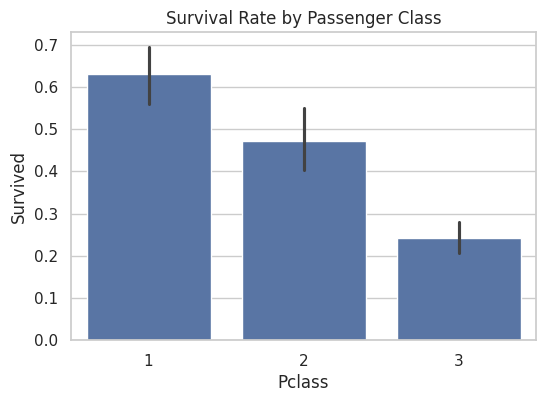

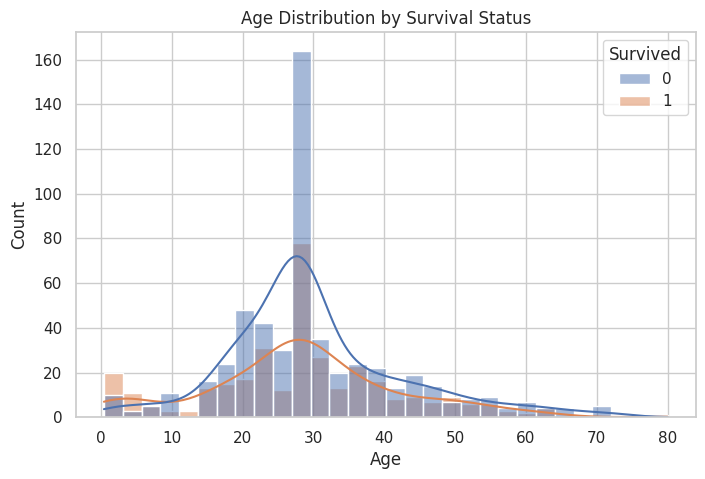

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Graph 1: Survival Rate by Passenger Class
plt.figure(figsize=(6, 4))
sns.barplot(x="Pclass", y="Survived", data=df)
plt.title("Survival Rate by Passenger Class")
plt.savefig("survival_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

# 2. Graph 2: Age Distribution by Survival
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", hue="Survived", kde=True, bins=30)
plt.title("Age Distribution by Survival Status")
plt.savefig("age_distribution.png", dpi=200, bbox_inches="tight")
plt.show()